In [8]:
#ДЗ 3 
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## Исходное изображение

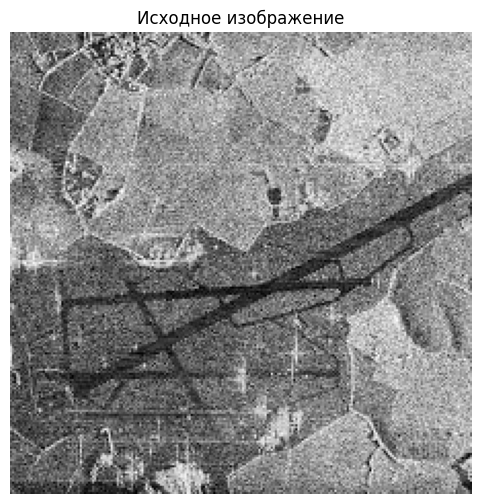

In [10]:
image = cv2.imread('sar_3.jpg')

if image is None:
    raise FileNotFoundError('Не найден файл sar_3.jpg')

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

## Выделение границ изображения

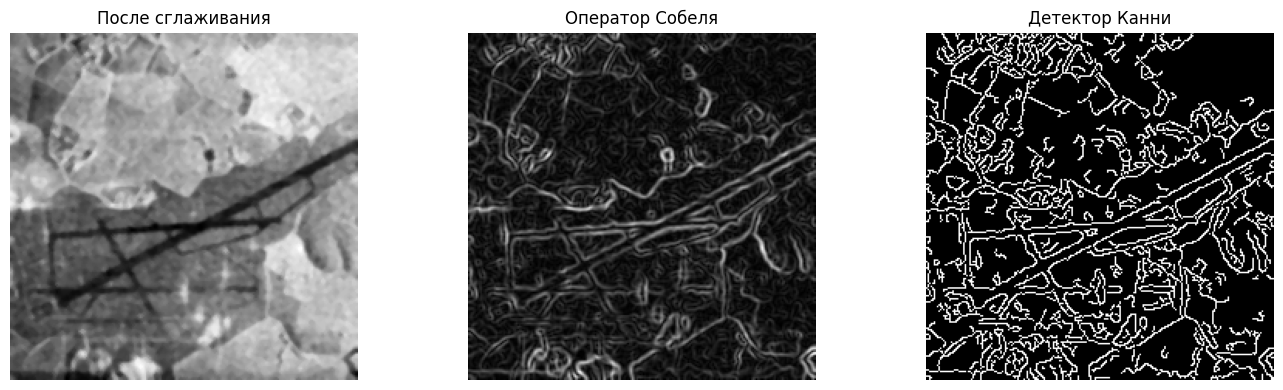

In [11]:

image_gauss = cv2.GaussianBlur(image_gray, (5, 5), 0)
image_smooth = cv2.medianBlur(image_gauss, 3)

grad_x = cv2.Sobel(image_smooth, cv2.CV_64F, 1, 0, ksize=3)
grad_y = cv2.Sobel(image_smooth, cv2.CV_64F, 0, 1, ksize=3)
grad = np.hypot(grad_x, grad_y)
sobel = cv2.convertScaleAbs(grad, alpha=255 / (grad.max() + 1e-10))

canny = cv2.Canny(image_smooth, 50, 100)


plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.imshow(image_smooth, cmap='gray')
plt.title('После сглаживания')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sobel, cmap='gray')
plt.title('Оператор Собеля')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(canny, cmap='gray')
plt.title('Детектор Канни')
plt.axis('off')

plt.tight_layout()
plt.show()

## Преобразование Хафа, поиск наиболее протяженного участка

Всего найдено отрезков: 116
Самый длинный отрезок: (45, 163) — (223, 69)
Длина: 201.30 пикселя


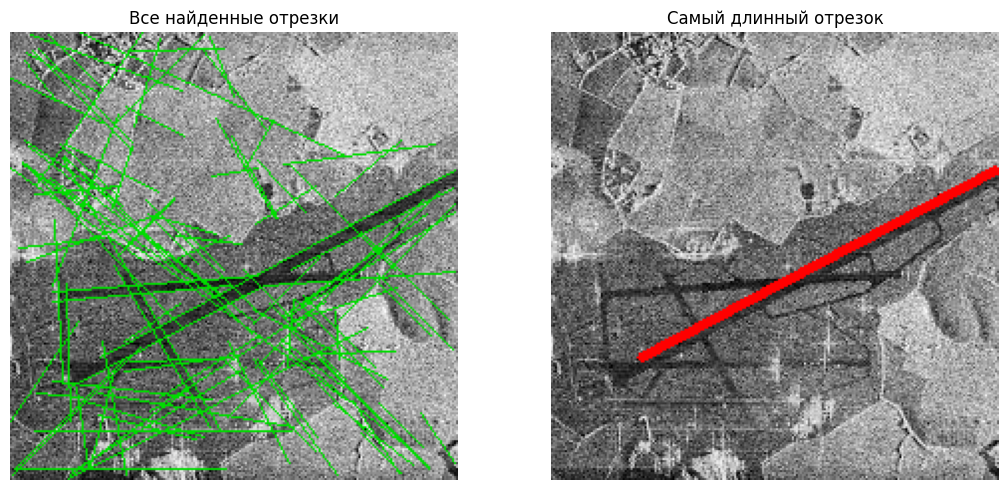

In [12]:

lines = cv2.HoughLinesP(canny, 1, np.pi / 180, threshold=50, minLineLength=20, maxLineGap=10)

segments = lines.reshape(-1, 4)
lengths = np.hypot(
    segments[:, 2] - segments[:, 0],
    segments[:, 3] - segments[:, 1]
)

best_index = int(np.argmax(lengths))
x1, y1, x2, y2 = map(
    int, segments[best_index]
)

print('Всего найдено отрезков:', len(segments))
print(f'Самый длинный отрезок: ' f'({x1}, {y1}) — ({x2}, {y2})')
print(f'Длина: {lengths[best_index]:.2f} пикселя')

image_all = cv2.cvtColor( image_gray, cv2.COLOR_GRAY2RGB)

for x_start, y_start, x_end, y_end in segments:
    cv2.line( image_all, (int(x_start), int(y_start)), (int(x_end), int(y_end)), (0, 220, 0), 1)

image_longest = cv2.cvtColor( image_gray, cv2.COLOR_GRAY2RGB)
cv2.line( image_longest, (x1, y1), (x2, y2), (255, 0, 0), 3)

plt.figure(figsize=(11, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_all)
plt.title('Все найденные отрезки')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_longest)
plt.title('Самый длинный отрезок')
plt.axis('off')

plt.tight_layout()
plt.show()

## Исследование алгоритмов бинаризации

Порог Отсу: 129


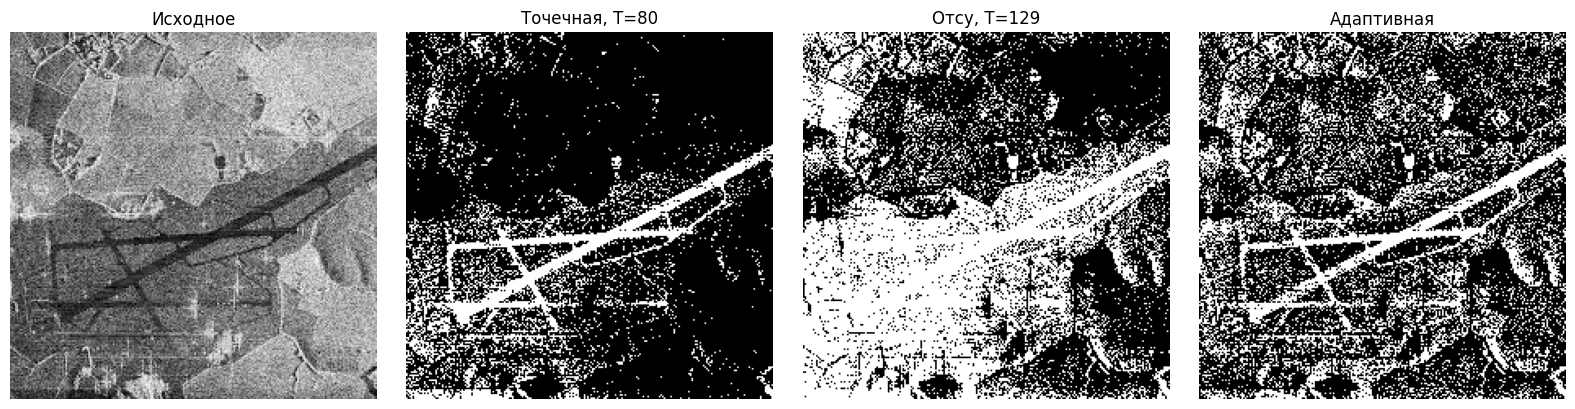

In [13]:
T = 80

_, bin_fixed = cv2.threshold(image_gray, T, 255, cv2.THRESH_BINARY_INV)

otsu_threshold, bin_otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

bin_adaptive = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 71, 15)

print(f'Порог Отсу: {otsu_threshold:.0f}')


plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(bin_fixed, cmap='gray')
plt.title(f'Точечная, T={T}')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(bin_otsu, cmap='gray')
plt.title(f'Отсу, T={otsu_threshold:.0f}')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(bin_adaptive, cmap='gray')
plt.title('Адаптивная')
plt.axis('off')

plt.tight_layout()
plt.show()

## Выделение участка дорожной полосы

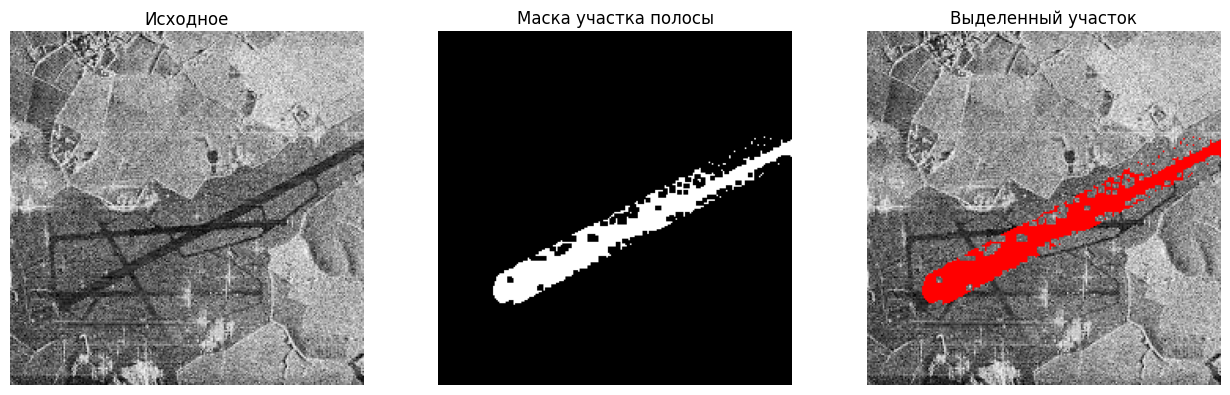

In [14]:
roi = np.zeros_like(image_gray)

cv2.line( roi, (x1, y1), (x2, y2), 255, 22)

road_mask = cv2.bitwise_and(bin_fixed, roi)
kernel = np.ones((3, 3), dtype=np.uint8)
road_mask = cv2.morphologyEx( road_mask, cv2.MORPH_CLOSE, kernel)

selected = cv2.cvtColor( image_gray, cv2.COLOR_GRAY2RGB)
selected[road_mask > 0] = (255, 0, 0)

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(road_mask, cmap='gray')
plt.title('Маска участка полосы')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(selected)
plt.title('Выделенный участок')
plt.axis('off')

plt.tight_layout()
plt.show()

# Для данного изображения лучше всего подошла точечная бинаризация